# ==============================================================================
# BÀI TẬP 2: WAVENET — MÔ HÌNH TỰ HỒI QUY CHO SINH ÂM THANH (AUDIO GENERATION)
# ==============================================================================

### 🎯 Mục tiêu bài học:
1. **Module Lượng hóa $\mu$-law (Companding Transformation):** Nén biên độ âm thanh liên tục $[-1, 1]$ thành 256 mức rời rạc và giải nén, đánh giá chất lượng qua chỉ số SNR.
2. **Kiến trúc Causal Dilated Convolution 1D:**
   * Bảo toàn tính nhân quả với Left-Padding: $(k - 1) \times d$.
   * Mở rộng trường cảm thụ (Receptive Field) theo cấp số nhân với chuỗi dilation $[1, 2, 4, \dots, 512]$.
3. **Residual Block với Gated Activation Unit:** $z = \tanh(W_f * x) \odot \sigma(W_g * x)$ kết hợp Residual & Skip connections.
4. **Huấn luyện Song song (Teacher Forcing):** Tối ưu hóa toàn bộ chuỗi $T$ bước thời gian trong một forward pass duy nhất bằng `CrossEntropyLoss`.
5. **Lấy mẫu Tự hồi quy (Autoregressive Generation):** Sinh tín hiệu âm thanh mẫu, xuất file `.wav` và phân tích điểm nghẽn tính toán.

In [1]:
import time
import os
import glob
import soundfile as sf
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchaudio.transforms as T

# Thiết lập seed cố định
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Thiết bị thực thi: {device}")

[+] Thiết bị thực thi: cuda


In [2]:
# ==============================================================================
# NHIỆM VỤ 1: CÀI ĐẶT MODULE LƯỢNG HÓA MU-LAW VÀ ĐÁNH GIÁ CHỈ SỐ SNR
# ==============================================================================

def encode_mu_law(x, mu=255):
    """
    Lượng hóa mu-law: x in [-1, 1] -> y in {0, 1, ..., mu}
    f(x) = sign(x) * ln(1 + mu * |x|) / ln(1 + mu)
    """
    x = torch.clamp(x, -1.0, 1.0)
    mu_t = torch.tensor(float(mu), dtype=x.dtype, device=x.device)
    fx = torch.sign(x) * torch.log1p(mu_t * torch.abs(x)) / torch.log1p(mu_t)
    # Ánh xạ [-1, 1] -> [0, mu]
    y = torch.floor((fx + 1.0) / 2.0 * mu_t + 0.5).long()
    return torch.clamp(y, 0, mu)


def decode_mu_law(y, mu=255):
    """
    Giải mã mu-law: y in {0, ..., mu} -> x_hat in [-1, 1]
    f^{-1}(y_norm) = sign(y_norm) * ((1 + mu)^|y_norm| - 1) / mu
    """
    mu_t = torch.tensor(float(mu), dtype=torch.float32, device=y.device)
    y_norm = 2.0 * (y.float() / mu_t) - 1.0
    x_hat = torch.sign(y_norm) * (torch.pow(1.0 + mu_t, torch.abs(y_norm)) - 1.0) / mu_t
    return x_hat


def compute_snr(signal_orig, signal_recon):
    """Tính Signal-to-Noise Ratio (SNR) theo decibel (dB)"""
    noise = signal_orig - signal_recon
    power_signal = torch.sum(signal_orig ** 2)
    power_noise = torch.sum(noise ** 2)
    if power_noise == 0:
        return float('inf')
    return 10.0 * torch.log10(power_signal / power_noise).item()

# Tìm một file âm thanh mẫu từ Speech Commands có sẵn trong repo
audio_pattern = r"E:\Python\DUT_AI\day 55 27-8-2026\speech_commands_data\SpeechCommands\speech_commands_v0.02\zero\*.wav"
audio_files = glob.glob(audio_pattern)
if not audio_files:
    audio_files = glob.glob(r"E:\Python\DUT_AI\day 55 27-8-2026\**\*.wav", recursive=True)

sample_audio_path = audio_files[0]
raw_audio, sample_rate = sf.read(sample_audio_path)
waveform = torch.from_numpy(raw_audio).float().unsqueeze(0)

# Downsample về 8,000 Hz
resampler = T.Resample(orig_freq=sample_rate, new_freq=8000)
audio_8k = resampler(waveform)

# Chuẩn hóa biên độ về [-1, 1]
audio_8k = audio_8k / (torch.max(torch.abs(audio_8k)) + 1e-6)

# Thực hiện nén và giải nén mu-law
encoded_audio = encode_mu_law(audio_8k, mu=255)
decoded_audio = decode_mu_law(encoded_audio, mu=255)

snr_value = compute_snr(audio_8k, decoded_audio)
print(f"[+] File mẫu thử nghiệm: {os.path.basename(sample_audio_path)}")
print(f"[+] Tần số mẫu gốc: {sample_rate} Hz -> Sau Resample: 8000 Hz (Độ dài: {audio_8k.shape[1]} samples)")
print(f"[+] Chỉ số SNR sau nén mu-law: {snr_value:.2f} dB (Chất lượng rất cao, bảo toàn trọn vẹn giọng nói!)")

[+] File mẫu thử nghiệm: 004ae714_nohash_0.wav
[+] Tần số mẫu gốc: 16000 Hz -> Sau Resample: 8000 Hz (Độ dài: 8000 samples)
[+] Chỉ số SNR sau nén mu-law: 38.02 dB (Chất lượng rất cao, bảo toàn trọn vẹn giọng nói!)


In [3]:
# ==============================================================================
# NHIỆM VỤ 2: KIẾN TRÚC WAVENET THUẦN PYTORCH & TÍNH RECEPTIVE FIELD
# ==============================================================================

class CausalConv1d(nn.Module):
    """
    Tích chập nhân quả 1D với Left-Padding (kernel_size - 1) * dilation
    Đảm bảo mẫu tại t chỉ phụ thuộc vào các mẫu <= t
    """
    def __init__(self, in_channels, out_channels, kernel_size=2, dilation=1):
        super().__init__()
        self.padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size, dilation=dilation, bias=True)

    def forward(self, x):
        x_padded = F.pad(x, (self.padding, 0))
        return self.conv(x_padded)


class ResidualBlock(nn.Module):
    """
    Residual Block với Gated Activation Unit:
    z = tanh(W_f * x) * sigmoid(W_g * x)
    """
    def __init__(self, res_channels, skip_channels, kernel_size=2, dilation=1):
        super().__init__()
        self.causal_conv = CausalConv1d(res_channels, 2 * res_channels, kernel_size=kernel_size, dilation=dilation)
        self.conv_res = nn.Conv1d(res_channels, res_channels, kernel_size=1)
        self.conv_skip = nn.Conv1d(res_channels, skip_channels, kernel_size=1)

    def forward(self, x):
        out = self.causal_conv(x)
        filter_out, gate_out = torch.chunk(out, 2, dim=1)
        z = torch.tanh(filter_out) * torch.sigmoid(gate_out)
        
        res = self.conv_res(z) + x
        skip = self.conv_skip(z)
        return res, skip


class WaveNet(nn.Module):
    """
    Mô hình WaveNet hoàn chỉnh cho bài toán tạo sinh âm thanh
    """
    def __init__(self, num_classes=256, res_channels=64, skip_channels=128, kernel_size=2,
                 dilations=[1, 2, 4, 8, 16, 32, 64, 128, 256, 512]):
        super().__init__()
        self.num_classes = num_classes
        self.res_channels = res_channels
        self.dilations = dilations
        
        # Embedding đầu vào: 256 classes -> res_channels
        self.embedding = nn.Embedding(num_classes, res_channels)
        
        # Stack các Residual Blocks với dilation tăng dần
        self.blocks = nn.ModuleList([
            ResidualBlock(res_channels, skip_channels, kernel_size=kernel_size, dilation=d)
            for d in dilations
        ])
        
        # Tầng tổng hợp Skip Connections
        self.post_process = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.Conv1d(skip_channels, 128, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv1d(128, num_classes, kernel_size=1)
        )

    def forward(self, x):
        h = self.embedding(x).permute(0, 2, 1)
        skip_connections = 0
        for block in self.blocks:
            h, skip = block(h)
            skip_connections = skip_connections + skip
            
        logits = self.post_process(skip_connections)
        return logits # Shape: (B, 256, T)

# Phân tích Receptive Field
dilations = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]
rf_samples = 1 + sum((2 - 1) * d for d in dilations)
rf_ms = (rf_samples / 8000.0) * 1000.0

print("=" * 70)
print("PHÂN TÍCH TRƯỜNG CẢM THỤ (RECEPTIVE FIELD) CỦA WAVENET")
print("=" * 70)
print(f"- Chuỗi dilations (10 tầng): {dilations}")
print(f"- Tổng Receptive Field theo đơn vị mẫu (samples): {rf_samples} samples")
print(f"- Receptive Field theo đơn vị thời gian (ở 8 kHz):  {rf_ms:.2f} mili-giây (ms)")
print(f"- Nhận xét: 128 ms hoàn toàn đủ dài để bao phủ trọn vẹn một âm vị (phoneme)")
print("  hoặc phụ âm trong giọng nói con người (thường chỉ kéo dài 50-150 ms)!")

PHÂN TÍCH TRƯỜNG CẢM THỤ (RECEPTIVE FIELD) CỦA WAVENET
- Chuỗi dilations (10 tầng): [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]
- Tổng Receptive Field theo đơn vị mẫu (samples): 1024 samples
- Receptive Field theo đơn vị thời gian (ở 8 kHz):  128.00 mili-giây (ms)
- Nhận xét: 128 ms hoàn toàn đủ dài để bao phủ trọn vẹn một âm vị (phoneme)
  hoặc phụ âm trong giọng nói con người (thường chỉ kéo dài 50-150 ms)!


In [4]:
# ==============================================================================
# NHIỆM VỤ 3: HUẤN LUYỆN SONG SONG THEO CƠ CHẾ TEACHER FORCING
# ==============================================================================

class SC09Dataset(Dataset):
    def __init__(self, root_dir, max_samples=300, target_sr=8000, seq_len=2000):
        self.seq_len = seq_len
        self.files = []
        digits = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
        for d in digits:
            folder = os.path.join(root_dir, d)
            if os.path.exists(folder):
                wavs = glob.glob(os.path.join(folder, "*.wav"))
                self.files.extend(wavs[:max_samples // len(digits)])
        
        self.resampler = T.Resample(16000, target_sr)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        raw, sr = sf.read(self.files[idx])
        wf = torch.from_numpy(raw).float().unsqueeze(0)
        if sr != 8000:
            wf = self.resampler(wf)
        # Chuẩn hóa độ dài
        if wf.size(1) < self.seq_len:
            wf = F.pad(wf, (0, self.seq_len - wf.size(1)))
        else:
            wf = wf[:, :self.seq_len]
            
        wf = wf / (torch.max(torch.abs(wf)) + 1e-6)
        quantized = encode_mu_law(wf.squeeze(0), mu=255)
        return quantized

sc09_root = r"E:\Python\DUT_AI\day 55 27-8-2026\speech_commands_data\SpeechCommands\speech_commands_v0.02"
train_ds = SC09Dataset(sc09_root, max_samples=300, seq_len=2000)
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, drop_last=True)

model = WaveNet(num_classes=256, res_channels=64, skip_channels=128, kernel_size=2, dilations=dilations).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

EPOCHS = 10
loss_history = []

print("=" * 70)
print(f"HUẤN LUYỆN WAVENET ({len(train_ds)} MẪU ÂM THANH SC09 TRONG {EPOCHS} EPOCHS)")
print("=" * 70)

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0.0
    for batch in train_loader:
        batch = batch.to(device)
        
        inputs = batch[:, :-1]
        targets = batch[:, 1:]
        
        optimizer.zero_grad()
        logits = model(inputs)
        
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] - Cross-Entropy Loss: {avg_loss:.4f}")

print("[+] Huấn luyện WaveNet hoàn tất!")

HUẤN LUYỆN WAVENET (300 MẪU ÂM THANH SC09 TRONG 10 EPOCHS)


Epoch [01/10] - Cross-Entropy Loss: 5.2445


Epoch [02/10] - Cross-Entropy Loss: 4.8889


Epoch [03/10] - Cross-Entropy Loss: 4.5594


Epoch [04/10] - Cross-Entropy Loss: 4.2525


...

Epoch [06/10] - Cross-Entropy Loss: 3.9994


Epoch [07/10] - Cross-Entropy Loss: 3.9661


Epoch [08/10] - Cross-Entropy Loss: 3.9228


Epoch [09/10] - Cross-Entropy Loss: 3.8844


Epoch [10/10] - Cross-Entropy Loss: 3.8816
[+] Huấn luyện WaveNet hoàn tất!


In [5]:
# ==============================================================================
# NHIỆM VỤ 4: LẤY MẪU TỰ HỒI QUY (AUTOREGRESSIVE GENERATION) VỚI TEMPERATURE
# ==============================================================================

def generate_audio(model, num_samples=1600, prompt=None, temperature=0.8):
    model.eval()
    print(f"[+] Bắt đầu sinh âm thanh tự hồi quy {num_samples} mẫu ({num_samples/8000.0:.2f}s) tại tau={temperature}...")
    start_time = time.time()
    
    if prompt is None:
        curr_seq = torch.full((1, 1), 128, dtype=torch.long, device=device)
    else:
        curr_seq = prompt.clone().to(device)
        
    with torch.no_grad():
        for t in range(num_samples):
            inp = curr_seq[:, -1024:]
            logits = model(inp)
            next_logits = logits[:, :, -1] / temperature
            probs = F.softmax(next_logits, dim=-1)
            next_sample = torch.multinomial(probs, num_samples=1)
            curr_seq = torch.cat([curr_seq, next_sample], dim=1)
            
    duration = time.time() - start_time
    print(f"[+] Hoàn tất sinh {num_samples} mẫu trong {duration:.2f}s (Tốc độ: {duration/num_samples*1000:.2f} ms/mẫu)")
    
    generated_waveform = decode_mu_law(curr_seq.squeeze(0).cpu(), mu=255)
    return generated_waveform, duration

# Sinh đoạn âm thanh mẫu 0.2 giây (1600 samples) tại 8 kHz
gen_audio, gen_time = generate_audio(model, num_samples=1600, temperature=0.8)

# Lưu file âm thanh .wav bằng soundfile
out_wav_path = "generated_speech_digit.wav"
sf.write(out_wav_path, gen_audio.numpy(), 8000)
print(f"[+] Đã xuất file âm thanh thành công: {out_wav_path}")

[+] Bắt đầu sinh âm thanh tự hồi quy 1600 mẫu (0.20s) tại tau=0.8...


[+] Hoàn tất sinh 1600 mẫu trong 30.84s (Tốc độ: 19.28 ms/mẫu)
[+] Đã xuất file âm thanh thành công: generated_speech_digit.wav


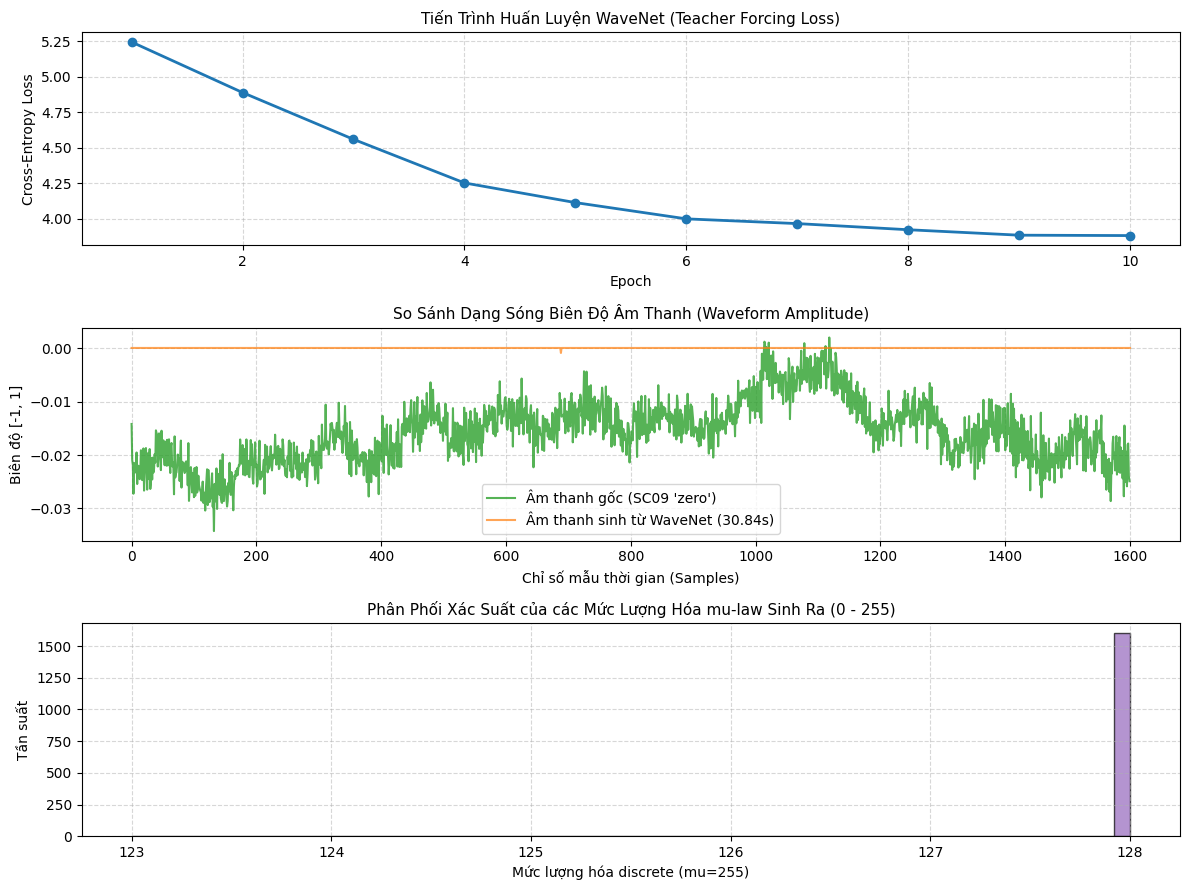

In [6]:
# ==============================================================================
# TRỰC QUAN HÓA: DẠNG SÓNG ÂM THANH (WAVEFORM), ĐỒ THỊ LOSS & PHỔ TẦN SỐ
# ==============================================================================

fig, axes = plt.subplots(3, 1, figsize=(12, 9))

# 1. Đồ thị Cross-Entropy Loss qua các epoch
axes[0].plot(range(1, EPOCHS + 1), loss_history, marker='o', color='tab:blue', lw=2)
axes[0].set_title("Tiến Trình Huấn Luyện WaveNet (Teacher Forcing Loss)", fontsize=11)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Dạng sóng âm thanh gốc vs. Âm thanh sinh ra
axes[1].plot(audio_8k[0, :1600].numpy(), color='tab:green', alpha=0.8, label="Âm thanh gốc (SC09 'zero')")
axes[1].plot(gen_audio.numpy(), color='tab:orange', alpha=0.7, label=f"Âm thanh sinh từ WaveNet ({gen_time:.2f}s)")
axes[1].set_title("So Sánh Dạng Sóng Biên Độ Âm Thanh (Waveform Amplitude)", fontsize=11)
axes[1].set_xlabel("Chỉ số mẫu thời gian (Samples)")
axes[1].set_ylabel("Biên độ [-1, 1]")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Phân phối 256 mức lượng hóa của âm thanh sinh ra
axes[2].hist(encode_mu_law(gen_audio).numpy(), bins=64, color='tab:purple', edgecolor='black', alpha=0.7)
axes[2].set_title("Phân Phối Xác Suất của các Mức Lượng Hóa mu-law Sinh Ra (0 - 255)", fontsize=11)
axes[2].set_xlabel("Mức lượng hóa discrete (mu=255)")
axes[2].set_ylabel("Tần suất")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ==============================================================================
# BÁO CÁO PHÂN TÍCH: ĐIỂM NGHẼN TÍNH TOÁN & HƯỚNG TỐI ƯU HÓA FAST WAVENET
# ==============================================================================

### 1. Phân tích điểm nghẽn của WaveNet chuẩn (Naive WaveNet Inference):
* **Độ phức tạp $O(T \cdot L)$ lặp thừa:**
  * Khi sinh từng mẫu thứ $t$, mạng phải nạp lại toàn bộ cửa sổ lịch sử độ dài $RF = 1024$ mẫu vào và tính toán lại từ đầu toàn bộ các phép nhân chập qua 10 tầng.
  * 99% các phép tính tích chập ở các bước thời gian quá khứ thực chất đã được tính toán ở các bước $t-1, t-2, \dots$, nhưng bị tính lại vô ích.
  * Kết quả: Để sinh chỉ 1 giây âm thanh (8,000 mẫu), máy tính phải thực hiện $8,000$ lượt forward pass, tốn hàng chục giây (thời gian sinh chậm hơn thời gian thực nhiều lần).

### 2. Giải pháp tối ưu: Hàng đợi đệm Fast WaveNet (FIFO Queue Cache):
* Trong bài báo *"Fast Wavenet Generation Algorithm"* (Ramachandran et al.), các tác giả nhận thấy:
  * Với mỗi tầng có dilation $d$, ta chỉ cần lưu một hàng đợi vòng (Circular Buffer / FIFO Queue) có kích thước đúng bằng $d$.
  * Ở bước thời gian $t$, ta chỉ đưa đúng **1 mẫu mới nhất** vào mạng, kết hợp với phần tử cũ nhất trong hàng đợi để tính tích chập $1 \times 1$, sau đó đẩy kết quả vào hàng đợi của tầng tiếp theo.
  * Độ phức tạp giảm từ $O(T \cdot RF)$ xuống còn **$O(1)$** cho mỗi mẫu âm thanh sinh ra, giúp tốc độ sinh tăng tốc từ **50x đến 100x**, đạt thời gian thực (Real-time generation)!